# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [37]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [38]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"This lab must be run in Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [39]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [40]:
print("No set_seed()")
print("randint 1:", random.randint(1, 100))
print("randint 2:", random.randint(1, 100))

numbers1 = list(range(10))
random.shuffle(numbers1)
print("shuffle 1:", numbers1)

numbers2 = list(range(10))
random.shuffle(numbers2)
print("shuffle 2:", numbers2)


print("\nWith set_seed() called before each operation")

set_seed()
print("randint 1:", random.randint(1, 100))

set_seed()
print("randint 2:", random.randint(1, 100))

set_seed()
numbers3 = list(range(10))
random.shuffle(numbers3)
print("shuffle 1:", numbers3)

set_seed()
numbers4 = list(range(10))
random.shuffle(numbers4)
print("shuffle 2:", numbers4)


print("\nWithout intermediate set_seed()")
set_seed()

print("randint 1:", random.randint(1, 100))
print("randint 2:", random.randint(1, 100))

numbers5 = list(range(10))
random.shuffle(numbers5)
print("shuffle 1:", numbers5)

numbers6 = list(range(10))
random.shuffle(numbers6)
print("shuffle 2:", numbers6)

No set_seed()
randint 1: 4
randint 2: 95
shuffle 1: [7, 6, 2, 9, 0, 5, 1, 8, 3, 4]
shuffle 2: [5, 3, 2, 8, 4, 6, 7, 1, 9, 0]

With set_seed() called before each operation
randint 1: 82
randint 2: 82
shuffle 1: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
shuffle 2: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]

Without intermediate set_seed()
randint 1: 82
randint 2: 15
shuffle 1: [7, 5, 2, 8, 9, 6, 1, 3, 4, 0]
shuffle 2: [5, 3, 2, 8, 4, 6, 7, 1, 9, 0]


Генератори псевдовипадкових чисел генерують послідовність на основі початкового значення - зерна.
Кожне наступне число залежить від попереднього, тобто генератор можна розглядати як рекурентну послідовність.

Як це проявляється в результатах коду:

1. До виклику `set_seed()`:
    * Генератор використовує системне джерело зерна.
    * Кожен виклик `randint()` та `shuffle()` дає нові, непередбачувані значення.

2. З повторним викликом `set_seed()` перед кожною операцією:
    * Функція `set_seed()` скидає внутрішній стан генераторів до вихідної точки `42`.
    * Оскільки генератор щоразу стартує з одного й того ж самого стану, перша згенерована дія за цим зерном завжди буде однаковою:
        * `randint 1` і `randint 2` видають однакове число.
        * `shuffle 1` і `shuffle 2` створюють однаковий порядок елементів у списку.

3. Без проміжного виклику `set_seed()`:
    * Генератор стартує з вихідного стану `42`, але після кожного виклику `randint()` чи `shuffle()` його внутрішній стан "зміщується вперед".
    * Числа всередині запуску залишаються різними, але ціла послідовність буде 100% відтворюваною при кожному перезапуску усієї програми.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [41]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Available device :", device_available)
print("Using            :", device)

if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"This lab must run on CPU, not GPU ({device})"

Available device : cpu
Using            : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [42]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"

os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)

print("Artifacts are saved to:", ARTIFACT_DIR)

Mounted at /content/drive
Artifacts are saved to: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [43]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape, zeros_arr.dtype)
print()
print(sevens_arr, sevens_arr.shape, sevens_arr.dtype)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64

[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [44]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print()
print(linspace_arr)

[ 0  2  4  6  8 10 12 14 16 18]

[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [45]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity, identity.ndim)
print()
print(random_ints, random_ints.ndim)

[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]] 2

[[6 3 7]
 [4 6 9]
 [2 6 7]] 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [46]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

mean = np.mean(scores)
std = np.std(scores)
z_scores = (scores - mean) / std

print("Mean:", mean, " Std:", std)
print("Z-scores:", z_scores)

Mean: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [47]:
arr = np.arange(1, 13)

matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Sum by rows:     ", row_sums)
print("Sum by columns:  ", col_sums)

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Sum by rows:      [10 26 42]
Sum by columns:   [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [48]:
df = pd.DataFrame({
    "name": ["Alice", "Bob", "Charlie", "David", "Emma"],
    "score": [95, 78, 88, 82, 61]
})

top = df[df["score"] > 80].sort_values("score", ascending=False)

print(top)

      name  score
0    Alice     95
2  Charlie     88
3    David     82


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [49]:
df["grade"] = df["score"].apply(
    lambda score: "A" if score >= 90 else "B" if score >= 75 else "C"
)

print(df)

      name  score grade
0    Alice     95     A
1      Bob     78     B
2  Charlie     88     B
3    David     82     B
4     Emma     61     C


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [50]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t, zeros_t.shape, zeros_t.dtype)
print()
print(sevens_t, sevens_t.shape, sevens_t.dtype)

tensor([[0., 0., 0.],
        [0., 0., 0.]]) torch.Size([2, 3]) torch.float32

tensor([[7, 7, 7],
        [7, 7, 7]]) torch.Size([2, 3]) torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [51]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)

tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [52]:
from_list = torch.tensor([[1, 2], [3, 4]])
set_seed()
random_t = torch.rand(3, 3)

print(from_list, from_list.shape, from_list.dtype, from_list.ndim)
print()
print(random_t, random_t.shape, random_t.dtype, random_t.ndim)

tensor([[1, 2],
        [3, 4]]) torch.Size([2, 2]) torch.int64 2

tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]]) torch.Size([3, 3]) torch.float32 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [53]:
n = 5.0

x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()

print("Automatic gradient:", x.grad.item())
print("Analytical gradient:", 2 * n)

Automatic gradient: 10.0
Analytical gradient: 10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [54]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for _ in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()

    with torch.no_grad():
        x -= lr * x.grad

    x.grad.zero_()

print(f"x = {x.item():.4f}  (min у x=3)")

x = 2.9654  (min у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

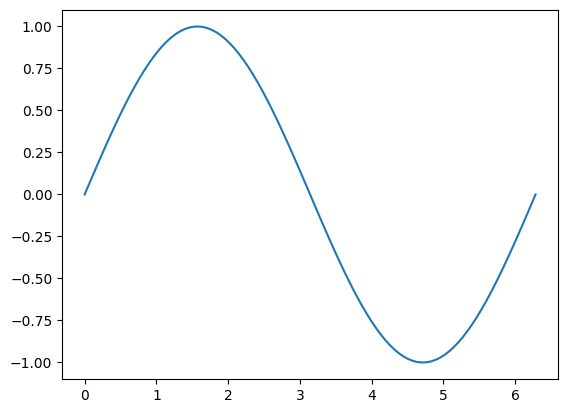

In [55]:
xs = np.linspace(0, 2*np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

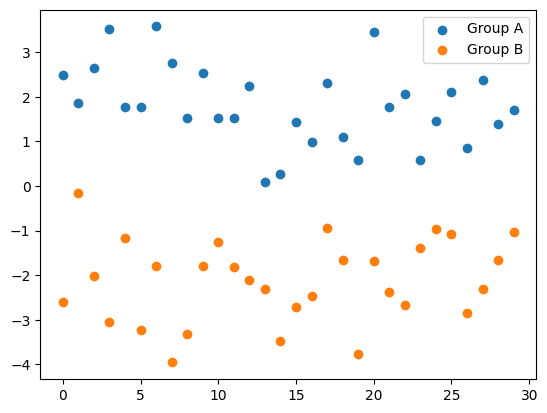

In [56]:
set_seed()
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

plt.scatter(range(len(group_a)), group_a, color="C0", label="Group A")
plt.scatter(range(len(group_b)), group_b, color="C1", label="Group B")

plt.legend()
plt.show()

---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [57]:
set_seed()

TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

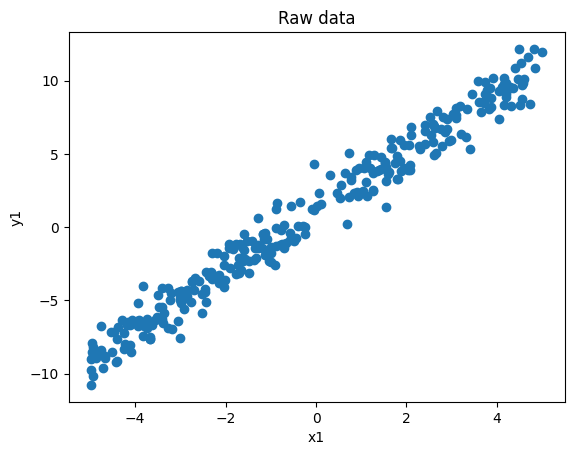

In [58]:
plt.scatter(x1, y1)
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Raw data")
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [59]:
set_seed()
perm = torch.randperm(TASK1_N)

x1_shuffled = x1[perm]
y1_shuffled = y1[perm]

train_size = int(0.70 * TASK1_N)
val_size = int(0.15 * TASK1_N)

x_train1 = x1_shuffled[:train_size]
y_train1 = y1_shuffled[:train_size]

x_val1 = x1_shuffled[train_size:train_size + val_size]
y_val1 = y1_shuffled[train_size:train_size + val_size]

x_test1 = x1_shuffled[train_size + val_size:]
y_test1 = y1_shuffled[train_size + val_size:]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")

train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [60]:
set_seed()

task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)
snapshots = []  # (epoch, w, b, y_line_pred)

ep_count = 100
sp_count = 3

for epoch in range(ep_count):
    optimizer.zero_grad()
    y_pred = task1_model(x_train1)
    loss = loss_fn(y_pred, y_train1)
    loss.backward()
    optimizer.step()

    if epoch % int(ep_count / sp_count) == 0 or epoch == ep_count - 1:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")

epoch    0  loss=14.358601  w=1.8412 (true 2.0)  b=0.8268 (true 1.0)
epoch   33  loss=0.974435  w=2.0083 (true 2.0)  b=1.1927 (true 1.0)
epoch   66  loss=0.974245  w=2.0088 (true 2.0)  b=1.2048 (true 1.0)
epoch   99  loss=0.974245  w=2.0088 (true 2.0)  b=1.2052 (true 1.0)


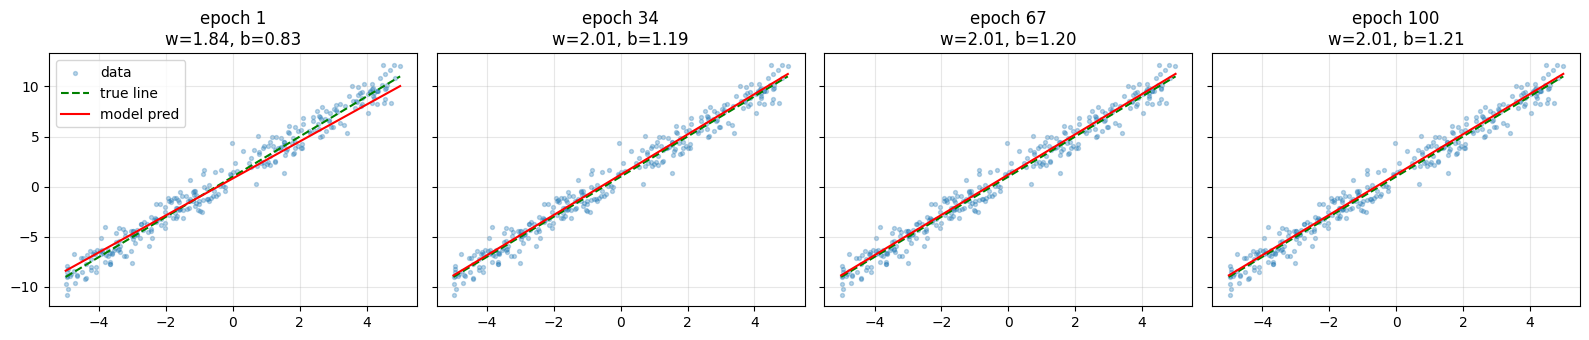

In [61]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="data")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true line")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="model pred")
    ax.set_title(f"epoch {epoch + 1}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Сценарій: Вплив кількості годин навчання на результати тесту

У цьому сценарії моделюється лінійна залежність між кількістю годин на тиждень, які студент витрачає на вивчення іноземної мови, та фінальним балом на стандартизованому тесті.

Закладені параметри:
* Зсув (b = 25.0) - базовий бал. Якщо людина взагалі не витрачає час на додаткове вивчення мови (0 годин), вона все одно може набрати певний мінімум, адже в тестах закритого типу завжди є ймовірність випадково вгадати правильні відповіді, а також студенти можуть мати залишкові фонові знання.
* Вага (w = 3.5) - коефіцієнт користі від навчання. Кожна додаткова година занять на тиждень приносить у середньому 3.5 додаткових бали на тесті. Регулярні заняття дають стабільний, але поступовий приріст знань, без надто різких стрибків. Для студента, який вчиться 20 годин на тиждень, бал складе $25 + (20 \times 3.5) = 95$
* Шум (std = 5.0) - природний розкид балів. Не всі люди навчаються з однаковою ефективністю, тому ідеальної лінії в реальності не буває.

### Генерація та збереження даних

In [62]:
TRUE_W = 3.5
TRUE_B = 25.0
NUM_SAMPLES = 300
NOISE_STD = 5.0
DATA_DIR = ARTIFACT_DIR

feature_data = np.random.uniform(0, 20, size=NUM_SAMPLES)
noise = np.random.normal(0, NOISE_STD, size=NUM_SAMPLES)

target_data = TRUE_W * feature_data + TRUE_B + noise

df = pd.DataFrame({
    "feature": feature_data,
    "target": target_data,
})

csv_file_path = os.path.join(DATA_DIR, "dataset.csv")
df.to_csv(csv_file_path, index=False)
print(f"Data saved to: {csv_file_path}")

Data saved to: /content/drive/MyDrive/ai_systems/lab1/dataset.csv


### Завантаження та візуалізація сирих даних

Dataset shape: (300, 2)
     feature     target
0   7.490802  51.445668
1  19.014286  88.292000
2  14.639879  86.959296
3  11.973170  70.075689
4   3.120373  25.795592


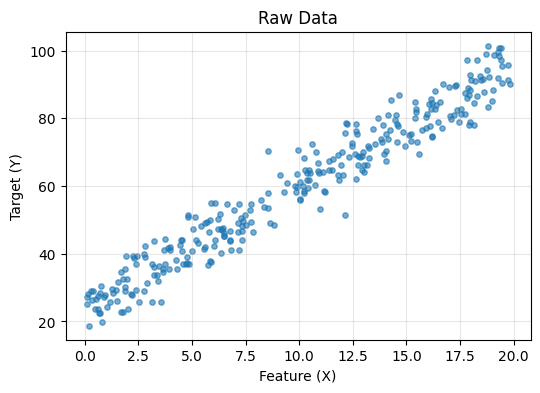

In [63]:
loaded_df = pd.read_csv(csv_file_path)
print(f"Dataset shape: {loaded_df.shape}")
print(loaded_df.head())

plt.figure(figsize=(6, 4))
plt.scatter(loaded_df["feature"], loaded_df["target"], s=15, alpha=0.6)
plt.xlabel("Feature (X)")
plt.ylabel("Target (Y)")
plt.title("Raw Data")
plt.grid(alpha=0.3)
plt.show()

### Організація логіки у перевикористовувані функції

In [64]:
def prepare_and_split_data(df, feature_col, target_col, train_ratio=0.7, val_ratio=0.15):
    """Converts dataframe columns to tensors, standardizes features, and splits the data."""
    x_raw = torch.tensor(df[feature_col].values, dtype=torch.float32).unsqueeze(1)
    y_raw = torch.tensor(df[target_col].values, dtype=torch.float32).unsqueeze(1)

    x_mean, x_std = x_raw.mean(), x_raw.std()
    x_normalized = (x_raw - x_mean) / x_std

    num_total = len(x_raw)
    perm = torch.randperm(num_total)
    n_train = int(train_ratio * num_total)
    n_val = int(val_ratio * num_total)

    train_idx = perm[:n_train]
    val_idx = perm[n_train:n_train + n_val]
    test_idx = perm[n_train + n_val:]

    splits = {
        "x_train": x_normalized[train_idx], "y_train": y_raw[train_idx],
        "x_val": x_normalized[val_idx],     "y_val": y_raw[val_idx],
        "x_test": x_normalized[test_idx],   "y_test": y_raw[test_idx]
    }

    stats = {"mean": x_mean, "std": x_std, "x_raw": x_raw, "y_raw": y_raw}

    return splits, stats

def train_linear_regression(splits, stats, epochs=100, lr=0.05, sp_count=3):
    """Trains a linear model and records snapshots for visualization."""
    model = torch.nn.Linear(in_features=1, out_features=1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()

    x_line_raw = torch.linspace(0, 20, 100).unsqueeze(1)
    x_line_norm = (x_line_raw - stats["mean"]) / stats["std"]
    snapshots = []

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        y_pred = model(splits["x_train"])
        loss = loss_fn(y_pred, splits["y_train"])
        loss.backward()
        optimizer.step()

        if epoch % int(ep_count / sp_count) == 0 or epoch == ep_count - 1:
            model.eval()
            with torch.no_grad():
                val_pred = model(splits["x_val"])
                val_loss = loss_fn(val_pred, splits["y_val"])
                y_line_pred = model(x_line_norm)

            w_eff = model.weight.item() / stats["std"].item()
            b_eff = model.bias.item() - model.weight.item() * stats["mean"].item() / stats["std"].item()

            snapshots.append((epoch, w_eff, b_eff, y_line_pred, x_line_raw))
            print(f"Epoch {epoch:3d} | Train Loss: {loss.item():.4f} | Val Loss: {val_loss.item():.4f} | "
                  f"w: {w_eff:.4f} (True: {TRUE_W}) | b: {b_eff:.4f} (True: {TRUE_B})")

    return model, snapshots

def evaluate_model(model, x_test, y_test):
    """Evaluates the model on the test dataset."""
    model.eval()
    loss_fn = torch.nn.MSELoss()
    with torch.no_grad():
        test_pred = model(x_test)
        test_loss = loss_fn(test_pred, y_test)
    print(f"\nFinal Test Loss (MSE): {test_loss.item():.4f}")
    return test_loss.item()

def plot_snapshots(snapshots, stats, true_w, true_b):
    """Plots the model's predictions over different epochs against the raw data."""
    fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)

    for ax, (epoch, w_eff, b_eff, y_line_pred, x_line_raw) in zip(axes, snapshots):
        y_line_true = true_w * x_line_raw + true_b

        ax.scatter(stats["x_raw"].numpy(), stats["y_raw"].numpy(), s=8, alpha=0.3, label="Data")
        ax.plot(x_line_raw.numpy(), y_line_true.numpy(), "g--", label="True Line")
        ax.plot(x_line_raw.numpy(), y_line_pred.numpy(), "r-", label="Model Pred")

        ax.set_title(f"Epoch {epoch + 1}\nw={w_eff:.2f}, b={b_eff:.2f}")
        ax.set_xlabel("Feature")
        ax.grid(alpha=0.3)

    axes[0].set_ylabel("Target")
    axes[0].legend()
    plt.tight_layout()
    plt.show()

### Виконання пайплайну тренування та тестування

Train: 210, Val: 45, Test: 45
Epoch   0 | Train Loss: 4066.8889 | Val Loss: 3223.0371 | w: 0.3268 (True: 3.5) | b: 2.7996 (True: 25.0)
Epoch  33 | Train Loss: 27.2873 | Val Loss: 25.9515 | w: 3.4840 (True: 3.5) | b: 23.3044 (True: 25.0)
Epoch  66 | Train Loss: 23.8521 | Val Loss: 21.8752 | w: 3.5612 (True: 3.5) | b: 24.0791 (True: 25.0)
Epoch  99 | Train Loss: 23.8491 | Val Loss: 21.8368 | w: 3.5630 (True: 3.5) | b: 24.1083 (True: 25.0)

Final Test Loss (MSE): 29.0066


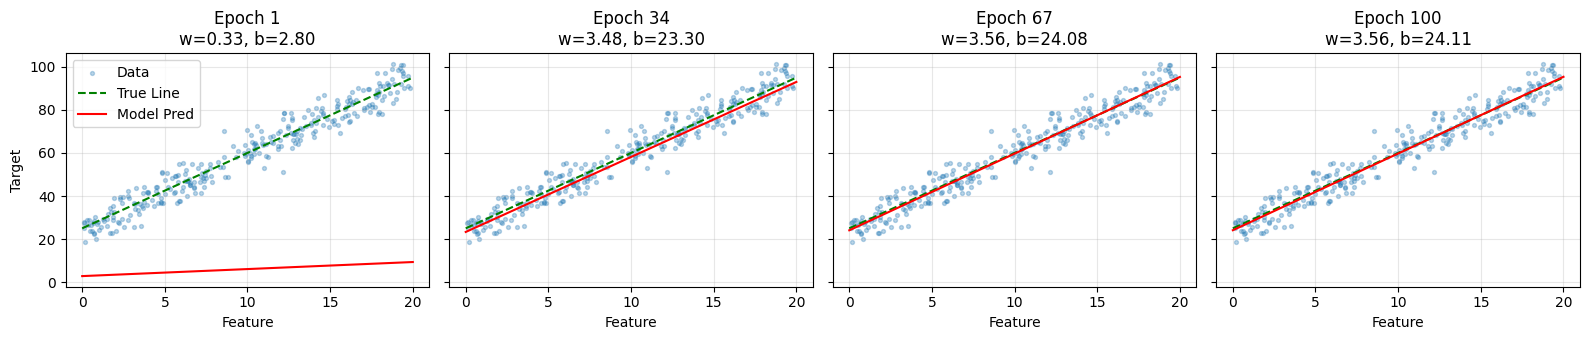

In [65]:
set_seed()

data_splits, data_stats = prepare_and_split_data(loaded_df, feature_col="feature", target_col="target")

print(f"Train: {len(data_splits['x_train'])}, "
      f"Val: {len(data_splits['x_val'])}, "
      f"Test: {len(data_splits['x_test'])}")

trained_model, training_snapshots = train_linear_regression(
    splits=data_splits,
    stats=data_stats,
    epochs=100,
    lr=0.05,
    sp_count=3
)

evaluate_model(trained_model, data_splits["x_test"], data_splits["y_test"])

plot_snapshots(training_snapshots, data_stats, TRUE_W, TRUE_B)

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [66]:
model_file_path = os.path.join(ARTIFACT_DIR, "model.pt")

torch.save({
    "state_dict": trained_model.state_dict(),
    "x_mean": data_stats["mean"].item(),
    "x_std": data_stats["std"].item(),
}, model_file_path)

print("Model saved to:", model_file_path)

Model saved to: /content/drive/MyDrive/ai_systems/lab1/model.pt


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [67]:
!pip install -q gradio
import gradio as gr

In [68]:
checkpoint = torch.load(model_file_path, weights_only=False)

loaded_model = torch.nn.Linear(in_features=1, out_features=1)
loaded_model.load_state_dict(checkpoint["state_dict"])
loaded_model.eval()

loaded_x_mean = checkpoint["x_mean"]
loaded_x_std = checkpoint["x_std"]

def predict_target(feature_value: float) -> float:
    x_input = torch.tensor([[feature_value]], dtype=torch.float32)

    x_input_norm = (x_input - loaded_x_mean) / loaded_x_std

    with torch.no_grad():
        y_pred = loaded_model(x_input_norm)

    return round(y_pred.item(), 1)

demo = gr.Interface(
    fn=predict_target,
    inputs=gr.Slider(minimum=0, maximum=20, value=10, step=0.1, label="Hours of studying"),
    outputs=gr.Number(label="Test score"),
    title="Linear Regression Demo",
    description="Interactive demonstration of a trained linear regression model. Move the slider to see how the model's prediction changes.",
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://426295f888f2bcb186.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```